# EDA Fakeddit (sous-ensemble)

Avant de lancer : Add Input -> ton dataset `fakeddit-subset`. Lance les cellules dans l'ordre et copie les sorties des cellules 2 a 6.

In [1]:
# Cellule 1 : imports et detection automatique des chemins
import os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Colab : remplace par P = '/content/' et IMG = '/content/images/'
hits = glob.glob('/kaggle/input/**/train.tsv', recursive=True)
assert hits, 'train.tsv introuvable : ajoute ton dataset avec Add Input'
P = os.path.dirname(hits[0]) + '/'
IMG = P + 'images/images/' if os.path.isdir(P + 'images/images') else P + 'images/'
print('P   =', P)
print('IMG =', IMG)

P   = /kaggle/input/datasets/sahnounsahnoun/fakenews/
IMG = /kaggle/input/datasets/sahnounsahnoun/fakenews/images/images/


In [3]:
# Cellule 2 : chargement et controle d'integrite (on veut 0 image manquante)
tr, va, te = [pd.read_csv(P + s + '.tsv', sep='\t') for s in ['train', 'val', 'test']]
have = {f[:-4] for f in os.listdir(IMG)}
print(len(have), 'images dans le dossier (attendu : environ 8196)')
for name, d in [('train', tr), ('val', va), ('test', te)]:
    missing = (~d['id'].astype(str).isin(have)).sum()
    print(name, len(d), 'exemples | images manquantes :', missing)

10711 images dans le dossier (attendu : environ 8196)
train 7792 exemples | images manquantes : 0
val 1469 exemples | images manquantes : 0
test 1450 exemples | images manquantes : 0


train 7792 {1: 0.507, 0: 0.493}
   6-way : {0: 3948, 1: 390, 2: 1183, 3: 141, 4: 1858, 5: 272}
val 1469 {1: 0.506, 0: 0.494}
   6-way : {0: 743, 1: 69, 2: 247, 3: 26, 4: 347, 5: 37}
test 1450 {1: 0.508, 0: 0.492}
   6-way : {0: 736, 1: 65, 2: 229, 3: 22, 4: 347, 5: 51}
              count  mean  std  min  25%  50%   75%   max
2_way_label                                              
0            3844.0   6.2  5.1  1.0  2.0  5.0   8.0  51.0
1            3948.0   9.4  5.5  1.0  6.0  9.0  12.0  56.0


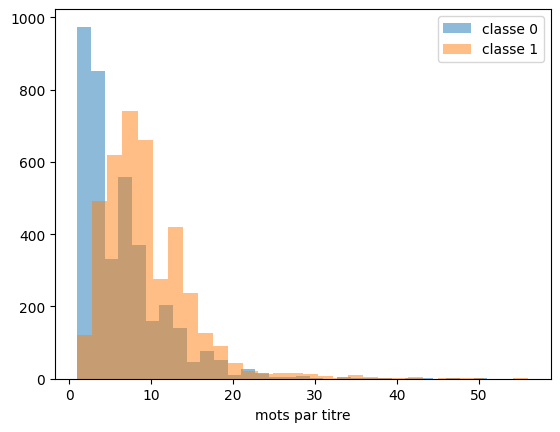

In [4]:
# Cellule 3 : equilibre des classes et longueur des titres
for name, d in [('train', tr), ('val', va), ('test', te)]:
    print(name, len(d), d['2_way_label'].value_counts(normalize=True).round(3).to_dict())
    print('   6-way :', d['6_way_label'].value_counts().sort_index().to_dict())

tr['n_words'] = tr['clean_title'].str.split().str.len()
print(tr.groupby('2_way_label')['n_words'].describe().round(1))
for lab in [0, 1]:
    plt.hist(tr.loc[tr['2_way_label'] == lab, 'n_words'], bins=30, alpha=0.5, label='classe ' + str(lab))
plt.xlabel('mots par titre'); plt.legend(); plt.show()

In [5]:
# Cellule 4 : subreddits (utile pour RQ4 et pour reperer les raccourcis)
sub = tr.groupby(['subreddit', '2_way_label']).size().unstack(fill_value=0)
sub['total'] = sub.sum(axis=1)
sub['part_classe1'] = (sub[1] / sub['total']).round(2)
print(sub.sort_values('total', ascending=False).head(15))
print('nombre de subreddits (train) :', tr['subreddit'].nunique())
print('subreddits du test absents du train :', set(te['subreddit']) - set(tr['subreddit']))

2_way_label               0     1  total  part_classe1
subreddit                                             
psbattle_artwork       1858     0   1858           0.0
mildlyinteresting         0  1540   1540           1.0
photoshopbattles          0   982    982           1.0
nottheonion               0   549    549           1.0
pareidolia              515     0    515           0.0
upliftingnews             0   443    443           1.0
fakehistoryporn         394     0    394           0.0
fakealbumcovers         250     0    250           0.0
misleadingthumbnails    167     0    167           0.0
propagandaposters       166     0    166           0.0
subredditsimulator      139     0    139           0.0
neutralnews               0   130    130           1.0
usnews                    0   115    115           1.0
usanews                   0   109    109           1.0
confusing_perspective   107     0    107           0.0
nombre de subreddits (train) : 21
subreddits du test absents du t

In [6]:
# Cellule 5 : periode temporelle (plan B pour la generalisation)
for name, d in [('train', tr), ('val', va), ('test', te)]:
    t = pd.to_datetime(d['created_utc'], unit='s')
    print(name, t.min().date(), '->', t.max().date())

train 2009-01-24 -> 2019-10-22
val 2012-02-04 -> 2019-10-22
test 2011-04-08 -> 2019-10-22


In [7]:
# Cellule 6 : fuite de donnees et doublons
print('titres communs train/test :', len(set(tr['clean_title']) & set(te['clean_title'])))
print('titres communs train/val  :', len(set(tr['clean_title']) & set(va['clean_title'])))
print('doublons dans le train    :', tr['clean_title'].duplicated().sum())
print('ids communs train/test    :', len(set(tr['id']) & set(te['id'])))

titres communs train/test : 18
titres communs train/val  : 23
doublons dans le train    : 220
ids communs train/test    : 0


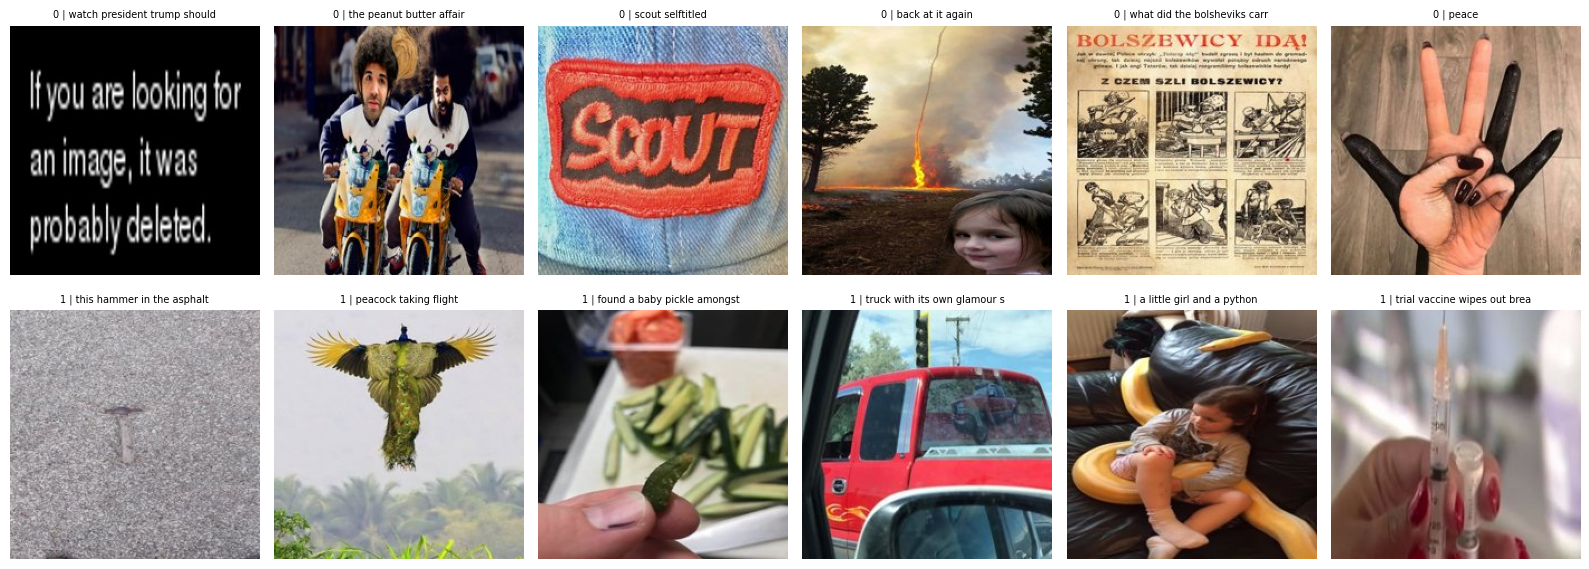

In [8]:
# Cellule 7 : grille d'images, 6 exemples par classe
fig, ax = plt.subplots(2, 6, figsize=(16, 6))
for r, lab in enumerate([0, 1]):
    ech = tr[tr['2_way_label'] == lab].sample(6, random_state=1)
    for c, (_, row) in enumerate(ech.iterrows()):
        ax[r][c].imshow(Image.open(IMG + str(row['id']) + '.jpg'))
        ax[r][c].axis('off')
        ax[r][c].set_title(str(lab) + ' | ' + row['clean_title'][:28], fontsize=7)
plt.tight_layout(); plt.show()

nombre d images identiques, les plus répétées : [480, 4, 4, 4, 4, 3, 3, 2]
480 images identiques | labels : {1: 330, 0: 150} | subreddits : {'mildlyinteresting': 286, 'fakehistoryporn': 45, 'photoshopbattles': 43, 'pareidolia': 37, 'fakealbumcovers': 28, 'confusing_perspective': 15, 'misleadingthumbnails': 13, 'subredditsimulator': 6, 'propagandaposters': 3, 'psbattle_artwork': 3, 'pic': 1}


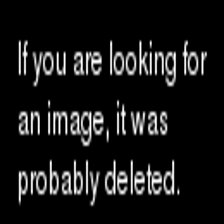

In [9]:
import hashlib, collections
h = {i: hashlib.md5(open(IMG + i + '.jpg', 'rb').read()).hexdigest() for i in have}
cnt = collections.Counter(h.values())
print('nombre d images identiques, les plus répétées :', [c for _, c in cnt.most_common(8)])

top = cnt.most_common(1)[0][0]
ids_top = [i for i, v in h.items() if v == top]
allsp = pd.concat([tr.assign(split='train'), va.assign(split='val'), te.assign(split='test')])
sel = allsp[allsp['id'].astype(str).isin(ids_top)]
print(len(ids_top), 'images identiques | labels :', sel['2_way_label'].value_counts().to_dict(),
      '| subreddits :', sel['subreddit'].value_counts().to_dict())
Image.open(IMG + ids_top[0] + '.jpg')